In [5]:
import random
import string
import numpy as np
import matplotlib.pyplot as plt

# Exploring the Birthday Paradox and Hash Collisions: A Theoretical and Experimental Study

## Table of Contents
1. Abstract
2. Introduction
3. Event-based probability
4. The complement rule
5. Birthday paradox
6. The Birthday Paradox represented by showing Python simulations
7. Reviewing the results
8. Birthday Attack and introduction of hash functions
9. Creating a simple controllable hash function
10. Creating a function to find a collision
11. Conclusion
12. Bibliography

##

## 1. Abstract
The journey we have gone through began with explaining simple probability and the complement rule, and then it moved toward the birthday paradox. A few Python simulations were run, showing how quickly the probability of matching birthdays increases dramatically when we put together a not very large number of people in a room. On the next step, the current study continued with explaining the birthday attack and the connection between the birthday paradox and information security was revealed. Also, a simple explanation of what a hash function is was made. Finally, a basic controllable hash function was shown and then collisions were demonstrated with experiments using different hash function lengths in bits.

## 2. Introduction
The main idea behind this project is to explain how certain mathematical concepts in the field of probability and combinatorics can be applied to understand vulnerability issues in cybersecurity. A very good example of an information security problem of major importance is when a collision happens in hash functions in case preventive measures are not taken. One of these measures can be choosing secure hash functions which can be implemented as a working solution. The hashing algorithm called SHA-256 is still considered to be safe to use due to the current computing hardware limitations.
If we get back to the issue with the collisions related to the hash functions, one of the cases with what could go wrong is when data is transferred through a computer network. If a secure hash algorithm is used then this ensures that a file which has been transferred from one computer to another computer through a computer network remains the same. In other words, the data integrity is preserved. Hash functions are widely used beyond network security. Common applications include password storage, hash tables, file integrity checks, blockchain technology, and digital signatures. Definitely, the main purpose of this project is not to explore all the possible ways in which hashing functions can be implemented. It will rather be a concentrated effort combined with a smooth transition, meaning gradually building up knowledge toward exploration of the subject topic (Cotton, 2023).

## 3. Event-based probability
First of all we need to clarify to ourselves that probability lives between 0 and 1, meaning consequently 0 percent and 100 percent. A probability of 0 means that an event is impossible, while a probability of 1 means that an event is certain to happen. Most events we meet in real life fall somewhere between these two extremes.
Let’s consider the following event-based probability example. If we roll a fair six-sided die, the probability of getting a specific number for example 6 is $\tfrac{1}{6}$ or about 16.67%. There are six possible outcomes and only one of them is favorable, so we simply divide the number of favorable outcomes by the total number of possible outcomes.

## 4. The complement rule
We already learnt one of the ways how to calculate the probability of something happening. We could also think of the chances of an event not occurring. Then this is called the complement rule (Webb, 2026). According to its definition, if two events are complementary then we can find the probability of one of the events happening if we subtract the probability of the other from 1. Of course it is true only when the two events cover all possible outcomes and cannot happen at the same time. The formula looks like this:
$$P(A) = 1 - P(\text{not } A)$$
This rule is very useful for the birthday paradox, because it is easier to calculate the probability that no one shares a birthday and then subtract it from 1.

## 5. Birthday paradox
Our initial intuition might lead us into wrong conclusions. For example, in case we go to a room full of people then we could wonder how many individuals it is necessary to be available at the premise just to have at least one birthday match between two people. Someone might incorrectly say that the minimum number of people must be at least around one hundred and eighty-three (half of 365). In reality the number is much smaller.
The classic result is that with only 23 people the probability of at least one shared birthday is slightly above 50%. The calculation uses the complement rule. First we calculate the probability that all 23 people have different birthdays:
$$P(\text{all different}) \approx 0.4927$$
Then we apply the complement rule:
$$P(\text{at least one shared birthday}) = 1 - 0.4927 \approx 0.5073 \quad (50.73\%)$$
Keeping the probability just above 50% is useful because it helps us identify the threshold at which a shared birthday becomes more likely than not.

## 

## 6. The Birthday Paradox represented by showing Python simulations
In the following Python code cells we are going to run 10 000 Python simulations for groups of imaginary people with different sizes. Each member of these groups will be assigned a random number representing the possible dates of birth in one year (from 1 to 365 inclusive). By running the experiment 10 000 times, we are supposed to get a better estimated matching probability. The main suggestion is that the probability of 23 people having at least one match is slightly above 50 percent. The code does not count all the available birthday matches in each group but it rather checks whether there is at least one shared birthday. The experiment will be run multiple times in order to figure out how the probability of two people having the same date of birth grows when the number of people in the imaginary group increases. The second suggestion is that the likelihood of having a match when 50 people are put in a room grows beyond 90 percent.

In [6]:
def shared_birthday(group_size: int) -> bool:
    #Returns True if at least two people who have a shared birthday.
    birthdays = [random.randint(1, 365) for _ in range(group_size)]
    return len(birthdays) != len(set(birthdays))

def simulate_birthday_paradox(group_size: int = 23, num_trials: int = 10000) -> float:
    #Simulate the Birthday Paradox.
    #Returns the estimated probability of at least one shared birthday.
    successes = 0
    for _ in range(num_trials):
        if shared_birthday(group_size):
            successes += 1
    return successes / num_trials

In [7]:
#Running the experiment with 20 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 20, num_trials = 10000)
print(f"Estimated probability with 20 people: {probability:.4f}")

Estimated probability with 20 people: 0.4068


In [8]:
#Running the experiment with 23 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 23, num_trials = 10000)
print(f"Estimated probability with 23 people: {probability:.4f}")

Estimated probability with 23 people: 0.5065


In [9]:
#Running the experiment with 30 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 30, num_trials = 10000)
print(f"Estimated probability with 30 people: {probability:.4f}")

Estimated probability with 30 people: 0.7053


In [10]:
#Running the experiment with 40 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 40, num_trials = 10000)
print(f"Estimated probability with 40 people: {probability:.4f}")

Estimated probability with 40 people: 0.8919


In [11]:
#Running the experiment with 50 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 50, num_trials = 10000)
print(f"Estimated probability with 50 people: {probability:.4f}")

Estimated probability with 50 people: 0.9737


In [12]:
#Running the experiment with 60 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 60, num_trials = 10000)
print(f"Estimated probability with 60 people: {probability:.4f}")

Estimated probability with 60 people: 0.9947


In [13]:
#Running the experiment with 70 people and 10,000 trials
probability = simulate_birthday_paradox(group_size = 70, num_trials = 10000)
print(f"Estimated probability with 70 people: {probability:.4f}")

Estimated probability with 70 people: 0.9992


## 7. Reviewing the results
After running the experiment multiple times with the following groups of people — 20, 23, 30, 40, 50, 60, and 70 — it can be said that 23 people in a room are enough to get at least one birthday match. The probability of this happening is slightly above 50%. It is quite interesting that a group of 20 people decreases the probability of matching to roughly 41 percent, but just 30 people in a room increase the probability to around 70%. What is even more intriguing is that only 50 people in one room could raise the likelihood of at least one match to approximately 97%. If the number of individuals is equal to 70 or more then the probability of at least one match is almost 100%. The following graph represents this.

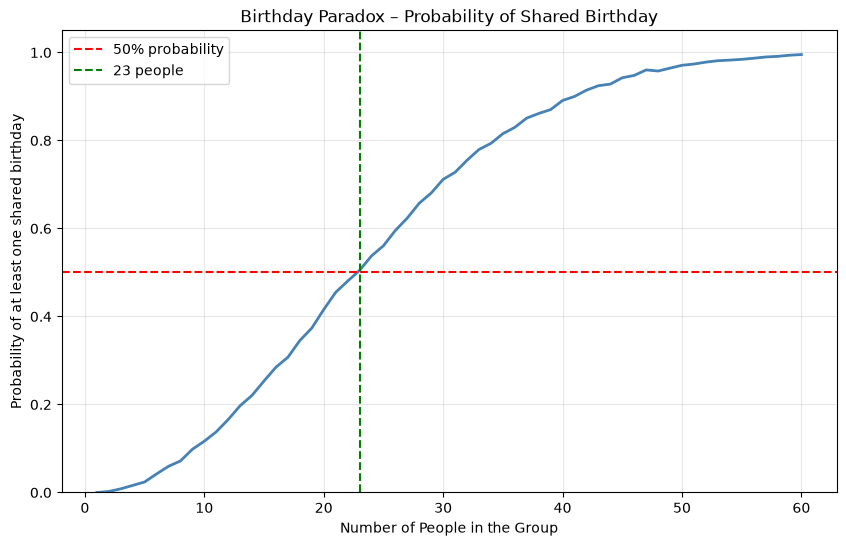

In [14]:
#Creating the data for the plot
group_sizes = list(range(1, 61))  # from 1 to 60 people
probabilities = [simulate_birthday_paradox(size) for size in group_sizes]

#The final graph
plt.figure(figsize = (10, 6))
plt.plot(group_sizes, probabilities, color = 'steelblue', linewidth = 2)
plt.axhline(y = 0.5, color = 'red', linestyle = '--', label = '50% probability')
plt.axvline(x = 23, color = 'green', linestyle = '--', label = '23 people')
plt.title('Birthday Paradox – Probability of Shared Birthday')
plt.xlabel('Number of People in the Group')
plt.ylabel('Probability of at least one shared birthday')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.ylim(0, 1.05)
plt.show()

In the graph above the blue curve represents how the probability grows as the group gets larger. The red dashed line shows the 50% probability and the green dashed line shows the 23 people mark.